## K-Mean Clustering
### Steps
#### 1- Decide n(K) clusters => It is the Work of the Programmer
#### 2- Init Centroids
#### 3- Assign clusters than go 4
#### 4- Move Centroids than again go 3
#### 5- Finish

### Disadvantage of K-Mean
#### It does not cluster by your own

In [28]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import pandas as pd


In [29]:
data=pd.read_csv(r"D:\BIKRAM_KUNDU\archive\Mall_Customers.csv")
data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [30]:
data.isna().sum()

CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [31]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Genre                   200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


### Feature Selection

In [32]:
X = data[['Annual Income (k$)', 'Spending Score (1-100)']]

In [33]:
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

In [34]:
inertias = []
K_range=range(1, 9)
for i in K_range:
    model = KMeans(n_clusters=i,random_state=42,n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

d:\BIKRAM_KUNDU\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\BIKRAM_KUNDU\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\BIKRAM_KUNDU\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
d:\BIKRAM_KUNDU\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

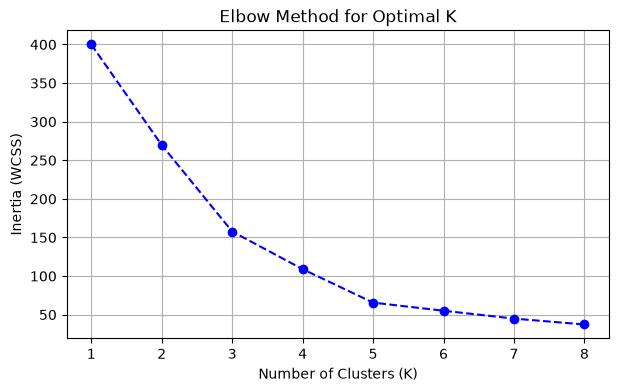

In [35]:
plt.figure(figsize=(7,4))
plt.plot(K_range,inertias,marker="o",linestyle="--",color="b")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method for Optimal K")
plt.grid(True)
plt.show()

In [38]:
# Find Model with Optimal K
kmeans = KMeans(n_clusters=5,random_state=42,n_init=10)
labels = kmeans.fit_predict(X_scaled)

d:\BIKRAM_KUNDU\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


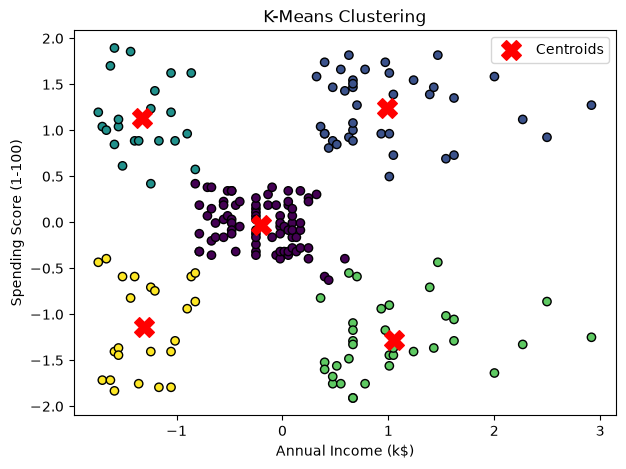

In [40]:
plt.figure(figsize=(7,5))
plt.scatter(X_scaled[:,0],X_scaled[:,1],c=labels,cmap="viridis",edgecolor="k")
plt.scatter(kmeans.cluster_centers_[:,0],kmeans.cluster_centers_[:,1],
            s=200,c="red",marker="X",label="Centroids")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("K-Means Clustering")
plt.legend()
plt.show()

In [ ]:
data['Cluster'] = labels

print(data[['Annual Income (k$)',
            'Spending Score (1-100)',
            'Cluster']].head(10))

print("\nNumber of Customers in Each Cluster:")
print(data['Cluster'].value_counts().sort_index())


   Annual Income (k$)  Spending Score (1-100)  Cluster
0                  15                      39        2
1                  15                      81        2
2                  16                       6        2
3                  16                      77        2
4                  17                      40        2
5                  17                      76        2
6                  18                       6        2
7                  18                      94        2
8                  19                       3        2
9                  19                      72        2

Number of Customers in Each Cluster:
Cluster
0     38
1     39
2    123
Name: count, dtype: int64
